# Step 4 (gimbal phase 1): Overlay on the clean MuJoCo runs

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | the three hand models: A (frictionless), B (viscous only), C (viscous and Coulomb), all from the 5 degree, 45 degree start; the MuJoCo runs with the same settings |
| **Unknown** | none, this is a comparison step |
| **Set to 0** | motor torque, noise (as before) |
| **NEW in this step** | the row alignment rule and the error metric |
| **What we get** | one figure and one table: hand against MuJoCo for A, B and C, plus a demonstration of why alignment matters |
| **Pass rule** | A and B: $10^{-6}$ rad; C: $10^{-3}$ rad (fixed before looking) |

## 2. The equations

**4.1 Row alignment.** In MuJoCo (and in the hand simulator) each log row is saved **after** the step. Row $k$ (counting from 0) is the state at

$$t_k=(k+1)\,\Delta t$$

We compare index to index: hand row $k$ with MuJoCo row $k$. Saving the initial state as a hand row would shift everything by one step and create a false error of about $\dot q\,\Delta t$.

**4.2 Error metric**

$$e_{k,i}=\left|q^{\text{hand}}_{k,i}-q^{\text{MuJoCo}}_{k,i}\right|,\qquad e_{\max}=\max_{k,i}e_{k,i}$$

**4.3 Pass rule**

$$e_{\max}\le\text{tolerance}\qquad(10^{-6}\ \text{rad for A and B},\ 10^{-3}\ \text{rad for C})$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $k$ | log row index (0 based) | 1 | known input | `row_index` |
| $t_k$ | time label of row $k$ | s | output | `time_axis` |
| $e_{k,i}$ | angle error | rad | output | `angle_error` |
| tolerance | pass level | rad | known input, fixed before looking | `TOLERANCE_RAD` |

## 3. Plug in, get out

```
hand A, B, C runs (steps 1 to 3)  +  MuJoCo A, B, C runs
   -> align index to index (4.1)
   -> 4.2 error arrays -> 4.3 compare with tolerance
   -> figure (overlay + error) and table
   -> extra: shift hand rows by one and show the false error
```

## 4. Conclusion

Phase 1 passes if all three rows of the table say PASS. At that point the hand model of the passive gimbal is trusted, and the actuator is added on top of it in phase 2.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "4_overlay_vs_mujoco"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/4_overlay_vs_mujoco


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)
COULOMB_FRICTION_VALUE = 0.02  # N*m, foundational (used where a run turns friction on)
friction_smoothing_width = 1e-3  # rad/s, foundational (tanh width, equation 3.2)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def coulomb_torque(rates, coulomb_friction):
    return -coulomb_friction * np.tanh(rates / friction_smoothing_width)  # N*m, equation 3.2


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    total_torque = total_torque + coulomb_torque(rates, coulomb_friction)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping, coulomb_friction)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0, coulomb_friction=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping, coulomb_friction)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping, coulomb_friction)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping, coulomb_friction)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping, coulomb_friction)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: run the fall, state saved AFTER each step
# What we have: start state, number of steps, friction settings
# What we want: angle, rate and energy logs (row k is the state at t = (k + 1) * time_step)
# Why: same logging as MuJoCo, so rows compare index to index (equation 4.1)
# ─────────────────────────────────────────────


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, coulomb_friction=0.0, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    motor_torque = np.zeros(2)  # placeholder, motors off in steps 1 to 4
    angle_log, rate_log, energy_log = [], [], []
    for step_index in range(n_steps):
        state = rk4_step(state, motor_torque, time_step, viscous_damping, coulomb_friction)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


A frictionless: rows = 949, max abs error = 4.44e-16 rad (tolerance 1e-06) PASS


B viscous only: rows = 961, max abs error = 4.44e-16 rad (tolerance 1e-06) PASS
C viscous + Coulomb: rows = 979, max abs error = 4.14e-04 rad (tolerance 1e-03) PASS


saved the figure


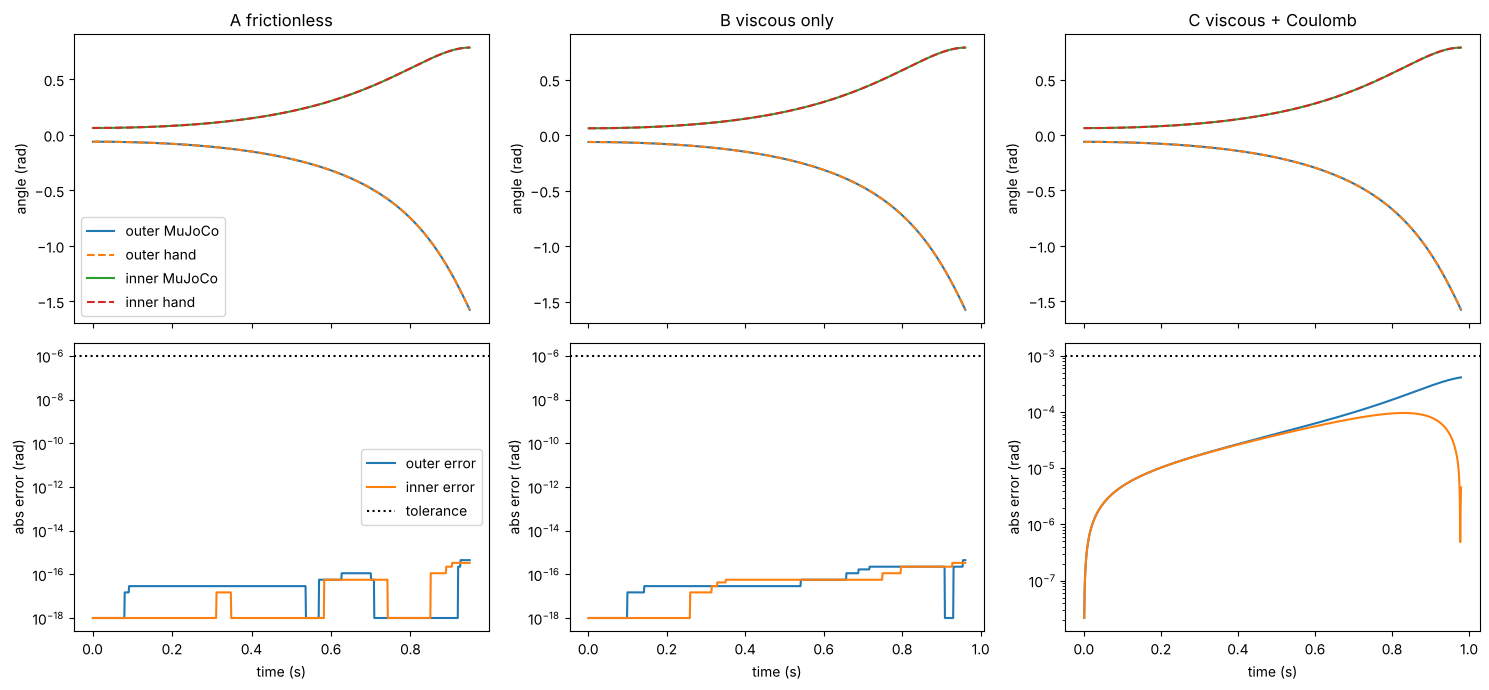


stage                  fall time (s)   max error (rad)   tolerance (rad)
A frictionless                 0.949          4.44e-16             1e-06
B viscous only                 0.961          4.44e-16             1e-06
C viscous + Coulomb            0.979          4.14e-04             1e-03
false error if the hand rows are shifted by one step: 7.66e-03 rad


In [8]:
# ─────────────────────────────────────────────
# STEP 8: overlay of stages A, B and C on the clean MuJoCo runs
# What we have: the three hand models (frictionless, viscous only, viscous plus Coulomb) and the matching MuJoCo runs
# What we want: one table and one figure; the false error if rows are shifted by one
# Why: phase 1 passes if all three rows say PASS (equations 4.1 to 4.3)
# ─────────────────────────────────────────────

MAX_STEPS = 30000
stages = [
    ("A frictionless", 0.0, 0.0, 1e-6),
    ("B viscous only", VISCOUS_DAMPING_VALUE, 0.0, 1e-6),
    ("C viscous + Coulomb", VISCOUS_DAMPING_VALUE, COULOMB_FRICTION_VALUE, 1e-3),
]  # (label, damping, friction, tolerance in rad), tolerances fixed before looking

figure, axes = plt.subplots(2, 3, figsize=(15, 7), sharex="col")
summary_rows = []
for column, (label, damping, friction, tolerance_rad) in enumerate(stages):
    hand_result = simulate(start_angles, start_rates, MAX_STEPS, damping, friction, stop_below_horizontal=True)
    mujoco_result = run_mujoco(start_angles, MAX_STEPS, damping, friction, stop_below_horizontal=True)
    angle_error = compare_angles(hand_result, mujoco_result, tolerance_rad, label)
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # equation 4.1
    axes[0, column].plot(time_axis, mujoco_result["angles"][:, 0], label="outer MuJoCo")
    axes[0, column].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer hand")
    axes[0, column].plot(time_axis, mujoco_result["angles"][:, 1], label="inner MuJoCo")
    axes[0, column].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner hand")
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel("angle (rad)")
    axes[1, column].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer error")
    axes[1, column].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner error")
    axes[1, column].axhline(tolerance_rad, color="k", linestyle=":", label="tolerance")
    axes[1, column].set_xlabel("time (s)")
    axes[1, column].set_ylabel("abs error (rad)")
    summary_rows.append((label, len(angle_error) * time_step, angle_error.max(), tolerance_rad))
axes[0, 0].legend()
axes[1, 0].legend()
figure.tight_layout()
figure.savefig(os.path.join(RESULT_DIR, f"phase1_overlay_{TIMESTAMP}.png"), dpi=150)
print("saved the figure")
plt.show()

print()
print(f"{'stage':<22}{'fall time (s)':>14}{'max error (rad)':>18}{'tolerance (rad)':>18}")
for label, fall_time, worst_error, tolerance_rad in summary_rows:
    print(f"{label:<22}{fall_time:>14.3f}{worst_error:>18.2e}{tolerance_rad:>18.0e}")

# equation 4.1: why index-to-index alignment matters (stage A, hand shifted by one row)
hand_a = simulate(start_angles, start_rates, MAX_STEPS, stop_below_horizontal=True)
mujoco_a = run_mujoco(start_angles, MAX_STEPS, stop_below_horizontal=True)
shifted_error = np.abs(hand_a["angles"][1:] - mujoco_a["angles"][:-1]).max()
print(f"false error if the hand rows are shifted by one step: {shifted_error:.2e} rad")
